<a href="https://colab.research.google.com/github/Jjanz43/MAT-422/blob/main/jjanz1_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# mat422 Jered Janz

import numpy as np
import matplotlib.pyplot as plt



Every matrix can be factored into three matrices


A = U\Sigma V^T,


where

 (U) contains orthonormal left singular vectors,
 (Sigma) contains the singular values,
 (V^T) contains orthonormal right singular vectors.

The singular values measure how much information is contained in each corresponding singular vector. Larger singular values indicate more important directions within the data.

In [10]:
A = np.array([
    [3.,1.],
    [2.,2.],
    [1.,3.]
])

U, s, Vt = np.linalg.svd(A, full_matrices=False)

Sigma = np.diag(s)

print("Matrix A")
print(A)

print("\nMatrix U")
print(U)

print("\nSingular Values")
print(s)

print("\nMatrix Sigma")
print(Sigma)

print("\nMatrix V^T")
print(Vt)

print("\nReconstruction")
print(U @ Sigma @ Vt)

print("\nVerification")
print(np.allclose(U @ Sigma @ Vt, A))

print("\nU^TU")
print(U.T @ U)

print("\nV^TV")
print(Vt @ Vt.T)

Matrix A
[[3. 1.]
 [2. 2.]
 [1. 3.]]

Matrix U
[[-0.5774  0.7071]
 [-0.5774  0.    ]
 [-0.5774 -0.7071]]

Singular Values
[4.899 2.   ]

Matrix Sigma
[[4.899 0.   ]
 [0.    2.   ]]

Matrix V^T
[[-0.7071 -0.7071]
 [ 0.7071 -0.7071]]

Reconstruction
[[3. 1.]
 [2. 2.]
 [1. 3.]]

Verification
True

U^TU
[[ 1. -0.]
 [-0.  1.]]

V^TV
[[ 1. -0.]
 [-0.  1.]]


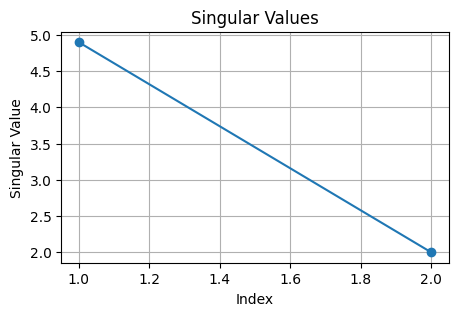

In [11]:
plt.figure(figsize=(5,3))

plt.plot(range(1,len(s)+1), s, marker='o')

plt.title("Singular Values")

plt.xlabel("Index")

plt.ylabel("Singular Value")

plt.grid(True)

plt.show()

The singular value decomposition successfully factors the matrix into


A = USigma V^T.


The verification confirms that multiplying these three matrices reconstructs the original matrix.

The matrices (U) and (V) are orthonormal because their transpose multiplied by themselves is approximately the identity matrix.

The singular value plot shows the relative importance of each singular value. Larger singular values represent directions that capture more of the matrix's structure, while smaller singular values contribute less information.

ne advantage of SVD is that we can approximate a matrix using only the largest singular values.

Keeping fewer singular values reduces the rank of the approximation while preserving much of the original information. This idea is widely used in image compression, recommendation systems, and data compression.


Rank 1 Approximation
[[2. 2.]
 [2. 2.]
 [2. 2.]]
Frobenius Error = 2.0

Rank 2 Approximation
[[3. 1.]
 [2. 2.]
 [1. 3.]]
Frobenius Error = 1.1957467920563633e-15


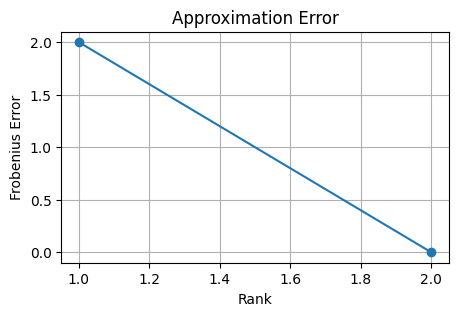

In [12]:
errors = []

for k in range(1, len(s)+1):

    Ak = U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

    error = np.linalg.norm(A - Ak, 'fro')

    errors.append(error)

    print(f"\nRank {k} Approximation")

    print(Ak)

    print("Frobenius Error =", error)

plt.figure(figsize=(5,3))

plt.plot(range(1,len(errors)+1), errors, marker='o')

plt.xlabel("Rank")

plt.ylabel("Frobenius Error")

plt.title("Approximation Error")

plt.grid(True)

plt.show()

Using fewer singular values creates a lower-rank approximation of the original matrix.

The Frobenius norm measures the difference between the approximation and the original matrix. As more singular values are included, the approximation error decreases.

When all singular values are retained, the approximation becomes identical to the original matrix and the reconstruction error approaches zero.

This demonstrates that the largest singular values contain the most important information within the matrix.

Principal Component Analysis (PCA) applies SVD to centered data. The data are first centered by subtracting the mean of each feature. SVD then identifies new orthogonal directions called principal components. The first principal component captures the greatest amount of variation, while each additional component explains the remaining variation.

Centered Data
[[-2.  -3.2]
 [-1.  -1.2]
 [ 0.  -0.2]
 [ 1.   1.8]
 [ 2.   2.8]]

Principal Directions
[[ 0.5512  0.8344]
 [ 0.8344 -0.5512]]

Scores
[[-3.7724  0.0949]
 [-1.5524 -0.173 ]
 [-0.1669  0.1102]
 [ 2.0531 -0.1577]
 [ 3.4386  0.1255]]

Explained Variance Ratio
[0.9972 0.0028]


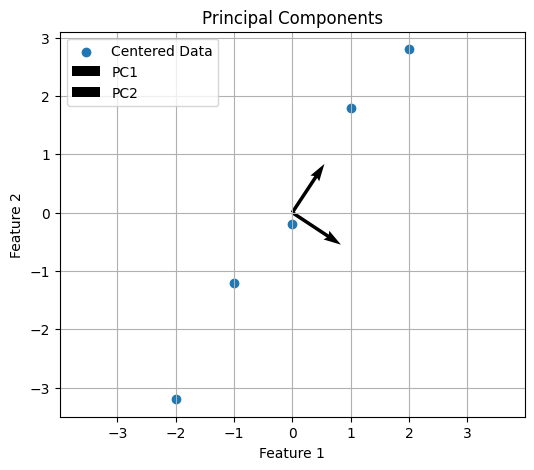

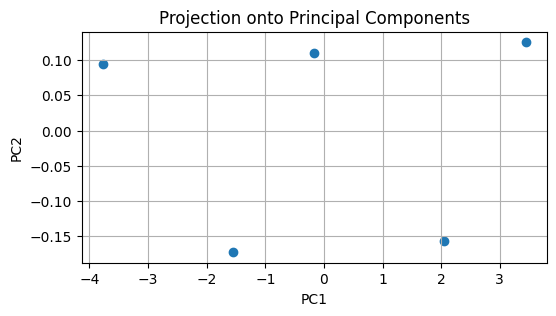

In [13]:
X = np.array([[2,3],[3,5],[4,6],[5,8],[6,9]], dtype=float)

X_centered = X - X.mean(axis=0)

U, s, Vt = np.linalg.svd(X_centered, full_matrices=False)

scores = X_centered @ Vt.T

variance = s**2

explained_variance = variance / variance.sum()

print("Centered Data")
print(X_centered)

print("\nPrincipal Directions")
print(Vt)

print("\nScores")
print(scores)

print("\nExplained Variance Ratio")
print(explained_variance)

plt.figure(figsize=(6,5))

plt.scatter(X_centered[:,0], X_centered[:,1], label="Centered Data")

origin = np.zeros(2)

for i in range(2):
    plt.quiver(origin[0], origin[1],
               Vt[i,0], Vt[i,1],
               angles='xy',
               scale_units='xy',
               scale=1,
               label=f"PC{i+1}")

plt.xlabel("Feature 1")

plt.ylabel("Feature 2")

plt.title("Principal Components")

plt.grid(True)

plt.axis("equal")

plt.legend()

plt.show()

plt.figure(figsize=(6,3))

plt.scatter(scores[:,0], scores[:,1])

plt.xlabel("PC1")

plt.ylabel("PC2")

plt.title("Projection onto Principal Components")

plt.grid(True)

plt.show()

## Analysis

The dataset was first centered by subtracting the mean of each feature. Centering ensures that PCA identifies directions of variation rather than being influenced by the location of the data. Applying SVD to the centered data produced the principal components, which are stored in the rows of (V^T). The first principal component corresponds to the direction of greatest variability within the dataset, while the second principal component explains the remaining variation. The explained variance ratios show how much of the total variability is captured by each principal component. Because the first ratio is much larger than the second, most of the information in this dataset is contained in the first principal component. The projection plot shows the original observations represented in the new principal component coordinate system.

# Reflection

This notebook demonstrated the three major concepts from Section 1.4.

- I decomposed a matrix using Singular Value Decomposition and verified that (A = USigma V^T).
- I confirmed that the matrices (U) and (V) are orthonormal by computing (U^TU\ and (VV^T).
- I created low-rank approximations using truncated SVD and compared the approximation errors using the Frobenius norm.
- I applied Principal Component Analysis by centering the data, computing the singular value decomposition, and interpreting the principal components.
- I visualized both the principal component directions and the transformed data.

## Submission Checklist

 All code executes without errors.
  All required Section 1.4 concepts are demonstrated.
 Numerical verification is included.
 Every code section includes mathematical explanations.
 Graphs are included for SVD, low-rank approximation, and PCA.
 I personalized at least one example or explanation.
 I ran every notebook cell from top to bottom.
-I saved the notebook directly from Google Colab to GitHub.
 The Open in Colab badge functions correctly.